In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

Two variables can have the same centre and very different variability. This part
measures the **spread** and the **shape** of a distribution, and introduces the boxplot
and the detection of outliers. We continue with the Madrid listings.

In [2]:
listings = pl.read_csv("data/processed/idealista/madrid_listings_2018.csv").select(
    "listing_id", "district", "zone", "condition",
    "price", "price_m2", "area_m2", "bedrooms", "bathrooms",
    "floor", "lift", "terrace", "construction_year", "dist_centre_km",
)

## Measures of dispersion

::: {#def-dispersion}
## Measures of dispersion

- **Range**: $R = x_{(n)} - x_{(1)}$.
- **Variance**: $\displaystyle s^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2$, the
  mean of the squared deviations from the mean.
- **Standard deviation**: $s = \sqrt{s^2}$, in the same units as the data.
- **Corrected (sample) variance**:
  $\displaystyle \hat{s}^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2 = \frac{n}{n-1}\,s^2$.
  It is the version used in statistical inference.
- **Interquartile range**: $IQR = Q_{0.75} - Q_{0.25}$, the width of the central half of
  the data.
- **Median absolute deviation**: $MAD = \text{median}_i\,|x_i - Me|$.
- **Coefficient of variation**, for positive variables: $CV = s / \bar{x}$.
:::

The variance, the standard deviation and the range depend on every observation; the
interquartile range and the MAD, like the median, ignore the extremes.

In [3]:
x = pl.col("price")

listings.select(
    range=x.max() - x.min(),
    variance=x.var(ddof=0),
    std_dev=x.std(ddof=0),
    IQR=x.quantile(0.75, "linear") - x.quantile(0.25, "linear"),
    MAD=(x - x.median()).abs().median(),
    CV=x.std(ddof=0) / x.mean(),
)

range,variance,std_dev,IQR,MAD,CV
"8,112,000.0","170,079,231,502.8","412,406.6","299,000.0","121,000.0",1.060


The variance is a huge number, in euros squared, which is why we report the standard
deviation: asking prices are typically about 412,000 € away from their mean, a spread
larger than the mean itself ($CV > 1$). The central half of the listings, however,
lies in an interval of about 300,000 €.

::: {.callout-important}
## Watch out for `ddof`

Polars (like pandas, R and Excel's `STDEV`) computes the **corrected** variance by
default, dividing by $n - 1$. To obtain $s^2$ as defined above we need `ddof=0`. With
75,735 listings the difference is negligible, but with small samples it is not
([exercise 4](04-exercises.ipynb)).
:::

### Properties of the variance

::: {#prp-variance-formula}
## Computational formula
$\displaystyle s^2 = \frac1n\sum_{i=1}^n x_i^2 - \bar x^2$, the mean of the squares minus the
square of the mean. In particular $\frac1n\sum_i x_i^2 \ge \bar x^2$.
:::

::: {.proof}
Take $c = 0$ in the least-squares property of the mean ([part 2](02-centre-position.ipynb#properties-of-the-mean-and-the-median)):
$\sum_i x_i^2 = \sum_i (x_i - \bar x)^2 + n\bar x^2$. Divide by $n$ and rearrange.
:::

The formula is convenient by hand and for grouped data,
$s^2 \approx \sum_i f_i x_i^2 - \big(\sum_i f_i x_i\big)^2$ with the class marks $x_i$. On a
computer it should be avoided when the mean is large compared with the standard
deviation: it subtracts two huge, almost equal numbers, and loses precision.

The standard deviation is a "typical" distance to the mean. The next result makes this
precise: few observations can be many standard deviations away from the mean.

::: {#prp-chebyshev}
## Chebyshev's inequality (for data)
For any data with $s > 0$ and any $k > 0$, the proportion of observations with
$|x_i - \bar x| \ge k s$ is at most $1/k^2$. Equivalently, at least $1 - 1/k^2$ of the
observations lie in the interval $(\bar x - ks, \bar x + ks)$.
:::

::: {.proof}
Let $A = \{i : |x_i - \bar x| \ge ks\}$ and $m = \#A$. Each $i \in A$ contributes at least
$k^2 s^2$ to the sum of squared deviations, and the other terms are non-negative, so
$$
n s^2 = \sum_{i=1}^n (x_i - \bar x)^2 \ge \sum_{i \in A}(x_i - \bar x)^2 \ge m\,k^2 s^2 .
$$
Dividing by $n k^2 s^2$ gives $m / n \le 1/k^2$.
:::

In [4]:
mean, sd = listings.select(m=pl.col("price").mean(), s=pl.col("price").std(ddof=0)).row(0)
pl.DataFrame([
    {"k": k,
     "proportion beyond k s": (listings["price"] - mean).abs().ge(k * sd).mean(),
     "Chebyshev bound 1/k^2": 1 / k**2}
    for k in [1.5, 2, 3, 5]
])

k,proportion beyond k s,Chebyshev bound 1/k^2
1.500,0.058,0.444
2.000,0.043,0.250
3.000,0.022,0.111
5.000,0.007,0.040


The bound holds for **any** data, whatever its shape, and is therefore conservative: for
the prices, the proportions are well below it. For bell-shaped data the "68–95–99.7
rule" of the normal distribution is much sharper, but it requires that shape.

::: {.callout-note}
## Historical note: Bienaymé and Chebyshev

The inequality was proved by Irénée-Jules Bienaymé in 1853 and, independently and
with a more general argument, by Pafnuty Chebyshev in 1867, who used it to give a
simple proof of the law of large numbers. It is the first example of a statistical
result that holds without assumptions on the shape of the distribution.
:::

### The coefficient of variation

The coefficient of variation has no units, so it compares the spread of variables
measured in different units: the price (€), the floor area (m²) and the price per m²
(€/m²):

In [5]:
cols = ["price", "area_m2", "price_m2"]
listings.select(pl.col(cols).std(ddof=0) / pl.col(cols).mean())

price,area_m2,price_m2
1.060,0.663,0.470


Total prices are relatively much more dispersed than prices per square metre. A large
part of the differences in price comes from the size of the dwellings: dividing by the
area removes it, and what remains (mostly location and quality) varies less. This is
why property markets are compared with the price per m².

### Variance within and between groups

How much of the variability of the price per m² is due to the district? The answer is
a decomposition of the variance, the descriptive core of the analysis of variance.

::: {#prp-variance-decomposition}
## Decomposition of the variance
If the observations are divided into $G$ groups with sizes $n_g$, means $\bar x_g$ and
variances $s_g^2$, then
$$
s^2 = \underbrace{\sum_{g=1}^G \frac{n_g}{n}\, s_g^2}_{\text{within groups}}
\;+\; \underbrace{\sum_{g=1}^G \frac{n_g}{n}\,(\bar x_g - \bar x)^2}_{\text{between groups}} .
$$
:::

::: {.proof}
Apply the least-squares property of the mean (part 2 of the proposition in
[part 2](02-centre-position.ipynb#properties-of-the-mean-and-the-median)) to the
observations of group $g$ with $c = \bar x$:
$\sum_{i \in g}(x_i - \bar x)^2 = n_g s_g^2 + n_g(\bar x_g - \bar x)^2$. Adding over the groups
gives $n s^2$ on the left; divide by $n$.
:::

The ratio $\eta^2 = (\text{between}) / s^2 \in [0, 1]$ is the **proportion of the variance
explained by the groups**: it is 1 if all the observations of each group are equal, and
0 if all the groups have the same mean.

In [6]:
overall_mean, overall_var = listings.select(
    m=pl.col("price_m2").mean(), v=pl.col("price_m2").var(ddof=0)
).row(0)
groups = listings.group_by("district").agg(
    n_g=pl.len(), mean_g=pl.col("price_m2").mean(), var_g=pl.col("price_m2").var(ddof=0)
)
n = listings.height
within = (groups["n_g"] * groups["var_g"]).sum() / n
between = (groups["n_g"] * (groups["mean_g"] - overall_mean) ** 2).sum() / n

print(f"total variance  : {overall_var:,.0f}")
print(f"within + between: {within:,.0f} + {between:,.0f} = {within + between:,.0f}")
print(f"eta^2 (share explained by the district): {between / overall_var:.2f}")

total variance  : 2,925,561
within + between: 1,197,123 + 1,728,438 = 2,925,561
eta^2 (share explained by the district): 0.59


The district alone accounts for almost 60 % of the variance of the price per m². The
rest is variation between dwellings of the same district: their exact location,
size, condition and quality.

## Measures of shape

::: {#def-shape}
## Skewness and kurtosis

- **Skewness coefficient**:
  $\displaystyle g_1 = \frac{\frac{1}{n}\sum (x_i-\bar{x})^3}{s^3}$. It is 0 for symmetric
  data, positive for a long tail to the right and negative for a long tail to the left.
- **Quartile (Bowley) skewness**:
  $\displaystyle \frac{(Q_{0.75} - Me) - (Me - Q_{0.25})}{Q_{0.75} - Q_{0.25}} \in [-1, 1]$, which
  compares the two halves of the box and is not affected by the extremes.
- **Excess kurtosis**:
  $\displaystyle g_2 = \frac{\frac{1}{n}\sum (x_i-\bar{x})^4}{s^4} - 3$. It compares the
  weight of the tails with that of the normal distribution, for which $g_2 = 0$.
:::

All three are invariant to changes of units ([exercise 6](04-exercises.ipynb)): they describe the shape, not
the location or the scale.

In [7]:
q1, me, q3 = [listings["price"].quantile(p, "linear") for p in (0.25, 0.5, 0.75)]
listings.select(
    skewness=pl.col("price").skew(),
    bowley=pl.lit((q3 - me - (me - q1)) / (q3 - q1)),
    kurtosis=pl.col("price").kurtosis(),  # already subtracts 3
)

skewness,bowley,kurtosis
4.074,0.331,29.472


Both skewness measures are positive. The kurtosis is very large: there are far more
extremely expensive dwellings than a bell-shaped distribution would have.

## Boxplot and outliers

The **boxplot** summarises in one graph the median, the quartiles and the possible
outliers:

- The box goes from $Q_{0.25}$ to $Q_{0.75}$, and the line inside it marks the median.
- The **fences** are $LF = Q_{0.25} - 1.5 \cdot IQR$ and $UF = Q_{0.75} + 1.5 \cdot IQR$, and
  the "whiskers" reach the most extreme observations within them.
- Observations outside $[LF, UF]$ are drawn one by one as **outliers**.

Boxplots are especially useful for **comparing groups**:

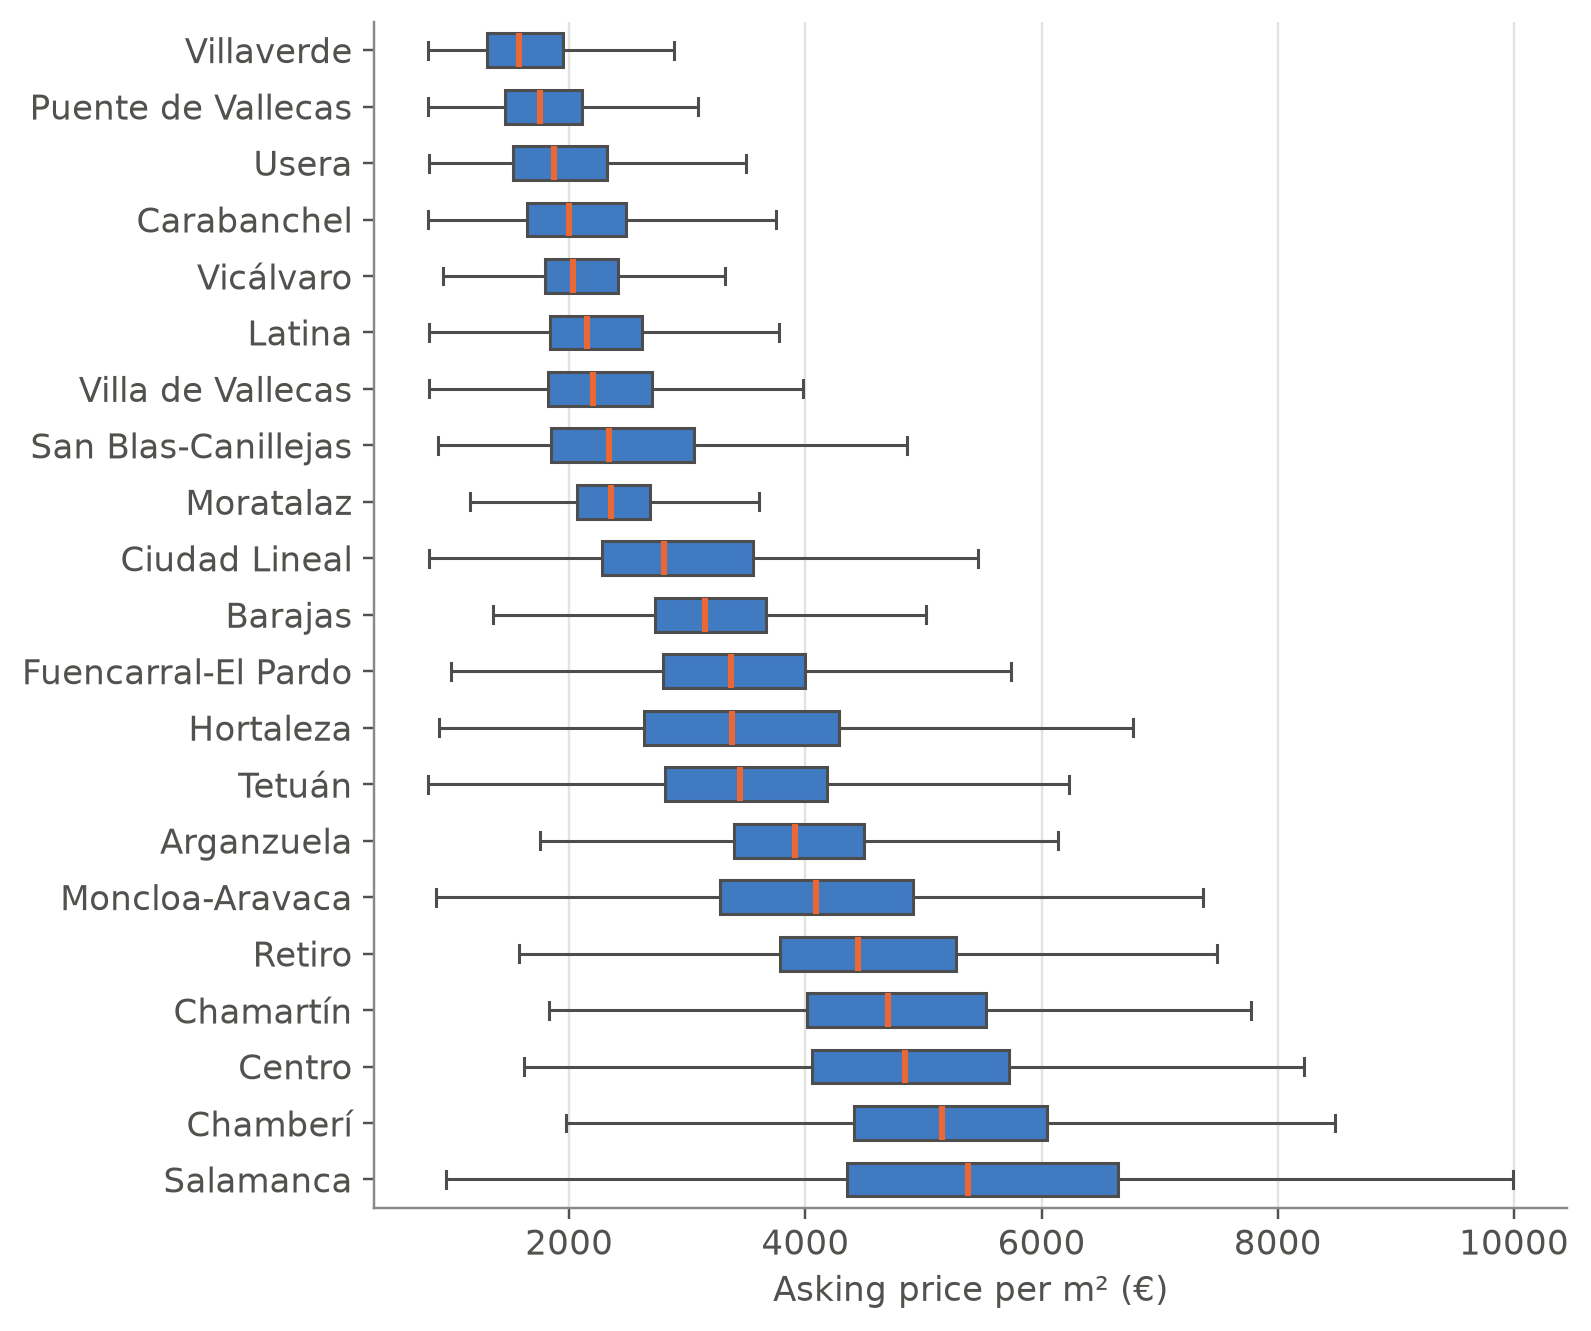

In [8]:
#| label: fig-boxplot-district
#| fig-cap: "Boxplots of the asking price per m² by district, sorted by the median. Outliers are not drawn."
order = (
    listings.group_by("district")
    .agg(median=pl.col("price_m2").median())
    .sort("median")["district"]
    .to_list()
)

fig, ax = plt.subplots(figsize=(7, 7))
sns.boxplot(x=listings["price_m2"].to_numpy(), y=listings["district"].to_numpy(),
            order=order, color=COLORS["blue"], showfliers=False, width=0.6,
            medianprops=dict(color=COLORS["orange"], linewidth=2), ax=ax)
ax.set_xlabel("Asking price per m² (€)")
ax.set_ylabel("")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

The median price per m² in Salamanca is more than three times that of Villaverde, and
the central districts occupy the top of the graph. The boxes also show what the
decomposition of the variance measured: the spread within each district is large
(the box of Salamanca spans about 2,300 €/m²).

::: {.callout-note}
## Historical note: Tukey's box-and-whisker plot

John Tukey introduced the box-and-whisker plot as part of his *exploratory data
analysis* [@tukey1977]. He wanted graphs that could be drawn by hand and were not
distorted by outliers, which is why the box is built from quartiles and not from the
mean and the standard deviation. The 1.5 × IQR rule was his practical choice
[@mcgill1978].
:::

In [9]:
iqr = q3 - q1
lf, uf = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = listings.filter(~pl.col("price").is_between(lf, uf))
print(f"Fences: [{lf:,.0f}, {uf:,.0f}] €  ·  outliers: {outliers.height:,} "
      f"({outliers.height / listings.height:.1%} of the listings)")

Fences: [-291,500, 904,500] €  ·  outliers: 5,512 (7.3% of the listings)


The lower fence is negative, so prices can only have outliers at the top, as is usual
in right-skewed distributions.

::: {.callout-warning}
## An outlier is not necessarily an error

An outlier may be an error (the dwelling with 93 bedrooms of
[part 1](01-freq-graphs.ipynb#discrete-variables)), but it may also be a genuinely
expensive dwelling. In a right-skewed distribution the 1.5 × IQR rule flags many valid
observations, here about one listing in fourteen. Before removing an observation we
have to understand why it is outlying.
:::

## Linear transformations and standardisation

::: {#prp-linear}
## Linear transformations
If $y_i = a + b\,x_i$, then $\bar{y} = a + b\,\bar{x}$, $s_y^2 = b^2 s_x^2$ and
$s_y = |b|\, s_x$. If moreover $b > 0$, every quantile satisfies
$Q_p(y) = a + b\,Q_p(x)$.
:::

::: {.proof}
$\bar y = \frac1n\sum_i (a + bx_i) = a + b\bar x$. Then $y_i - \bar y = b(x_i - \bar x)$, so
$s_y^2 = \frac1n\sum_i b^2(x_i-\bar x)^2 = b^2s_x^2$. The statement on quantiles is
the result on monotone transformations of
[part 2](02-centre-position.ipynb#measures-of-position-quantiles), with the increasing
function $g(x) = a + bx$.
:::

Adding a constant moves the centre but not the spread; multiplying by a constant
multiplies both. A special case is **standardisation**,
$$
z_i = \frac{x_i - \bar{x}}{s_x}, \quad\text{that is,}\quad a = -\frac{\bar x}{s_x},\ b = \frac1{s_x},
$$
which by @prp-linear gives $\bar z = 0$ and $s_z = 1$. The value $z_i$ says how many
standard deviations observation $i$ is above or below the mean, and allows comparing
observations of different variables. Is a flat of 150 m² more unusual in size than a
flat of 600,000 € is in price?

In [10]:
def z_score(column: str, value: float) -> float:
    x = listings[column]
    return (value - x.mean()) / x.std(ddof=0)

def percentile_rank(column: str, value: float) -> float:
    return (listings[column] <= value).mean()

for column, value in [("area_m2", 150), ("price", 600_000)]:
    print(f"{column:>8} = {value:>7,}: z = {z_score(column, value):.2f}, "
          f"F_n = {percentile_rank(column, value):.3f}")

 area_m2 =     150: z = 0.75, F_n = 0.871
   price = 600,000: z = 0.51, F_n = 0.835


Both measures agree that the flat of 150 m² is the more unusual one, but they say it
differently: $z$ measures distances in standard deviations, and $F_n$ the proportion of
listings below. With skewed variables the second is easier to interpret.

## Summary of the topic

| Type of variable | Tables | Graphs | Measures |
|---|---|---|---|
| Qualitative nominal | $n_i$, $f_i$ | Bar chart | Mode |
| Qualitative ordinal | $n_i$, $f_i$, $N_i$, $F_i$ | Bar chart | Mode, median, quantiles |
| Quantitative discrete | $n_i$, $f_i$, $N_i$, $F_i$ | Bar chart, $F_n$ | All |
| Quantitative continuous | By classes | Histogram, $F_n$, boxplot | All |

: Tables, graphs and measures for each type of variable.

The exercises for this topic are in [part 4](04-exercises.ipynb).

## References {.unnumbered}

::: {#refs}
:::